# 10 · Final evaluation: tuned models on an untouched confirmation set

Notebooks 05–09 were exploratory: one test set was used many times, the SVM regularisation was fixed (C = 1),
and the rotation-invariant 1P1Q variant was designed after seeing results. This notebook fixes all three.

**Protocol (decided before running):**
1. **Configurations are frozen** (list below). No configuration is added or dropped after seeing these results.
2. **All hyperparameters are chosen by 5-fold cross-validation on each 400-jet training subsample only**
   (quantum: SVM C, and f for 1P1Q; classical: C and γ for RBF-SVM, tree settings for BDT). Preprocessing is fitted on the training subsample.
3. **Confirmation set:** all quark/gluon jets of a second, never-used file of the same dataset. Each tuned model is evaluated on it **once**.
   The development test set of file 1 is also reported for comparison.
4. pT-binned AUC on the confirmation set.

Same 5 seeds, same balanced 400-jet training subsamples (from file 1) as before.

In [1]:
import sys
sys.path.insert(0, "src")

import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

from jet_data import (load_jets, select_quark_gluon, feature_matrix, event_level_split, balanced_subsample,
                      leading_constituents, BOOKKEEPING, PF_KEYS)
from kernels import (KERNELS, preprocess, onep1q_states, onep1q_kernel, angle_kernel, shot_noise)
from figure_style import set_style, save, COLORS

set_style()
SEED = 42
SEEDS = [0, 1, 2, 3, 4]
N_PER_CLASS = 200
N_CONST = 10
QGL_INPUTS = ("QG_mult", "QG_ptD", "QG_axis2")
C_GRID = np.logspace(-2, 6, 9)                       # 0.01 ... 1e6 (concentrated kernels may need large C)
F_GRID = np.round(np.logspace(0, 2.5, 12), 2)        # 1 ... 316
SHOTS = [100, 1000]
MAX_ITER = 200_000                                  # caps solver time at very large C; unconverged fits just score worse in CV
DEV_PATH = Path("Data/JetNtuple_RunIISummer16_13TeV_MC_1.h5")
CONFIRM_PATH = Path("Data/JetNtuple_RunIISummer16_13TeV_MC_10.h5")   # second, never-used file of record 12100
RESULTS = Path("results")
assert CONFIRM_PATH.exists(), f"confirmation file not found: {CONFIRM_PATH}"

COLUMNS = QGL_INPUTS + ("jetPt", "jetQGl")
def load(path):
    jets = select_quark_gluon(load_jets(path=path, features=COLUMNS, extra=BOOKKEEPING + PF_KEYS), require_loose_id=True)
    z, de, dp, _ = leading_constituents(jets, n_max=N_CONST)
    return {"y": jets["label"], "X": feature_matrix(jets, features=QGL_INPUTS), "pt": np.asarray(jets["jetPt"], float),
            "qgl": np.asarray(jets["jetQGl"], float), "z": z, "de": de, "dp": dp, "dr": np.sqrt(de**2 + dp**2), "jets": jets}

dev = load(DEV_PATH)
conf = load(CONFIRM_PATH)
train, test = event_level_split(dev["jets"], test_fraction=0.3, seed=SEED)
dev_test = np.flatnonzero(test)
print(f"development file: {len(dev['y'])} jets (train {int(train.sum())}, test {len(dev_test)})")
print(f"confirmation file: {len(conf['y'])} jets, quark fraction {conf['y'].mean():.3f}")

development file: 13912 jets (train 9729, test 4183)
confirmation file: 69810 jets, quark fraction 0.372


## 1. Frozen configurations

In [2]:
# name -> (family, how to build the kernel)
QUANTUM = {
    "amplitude, raw":            ("amplitude", "qgl", "raw"),
    "amplitude, standardised":   ("amplitude", "qgl", "standard"),
    "amplitude, min-max":        ("amplitude", "qgl", "minmax"),
    "angle, robust + YJ":        ("angle", "qgl", "robust_yj"),
    "angle, min-max":            ("angle", "qgl", "minmax"),
    "1P1Q (original)":           ("1P1Q", "const", "original"),
    "1P1Q rotation-invariant":   ("1P1Q", "const", "invariant"),
}

def kernel_builder(name, train_idx, f=None):
    family, inputs, variant = QUANTUM[name]
    if inputs == "qgl":
        Xtr = dev["X"][train_idx]
        def transform(X):
            return preprocess(variant, Xtr, X)[1]
        A = transform(Xtr)
        k = KERNELS[family]
        return lambda D, rows: k(transform(D["X"][rows]), A), k(A, A)
    if variant == "original":
        st = lambda D, rows: onep1q_states(D["z"][rows], D["de"][rows], D["dp"][rows], f)
        SA = st(dev, train_idx)
        return lambda D, rows: onep1q_kernel(st(D, rows), SA), onep1q_kernel(SA, SA)
    ang = lambda D, rows: f * D["z"][rows] * D["dr"][rows]
    A = ang(dev, train_idx)
    return lambda D, rows: angle_kernel(ang(D, rows), A), angle_kernel(A, A)

def cv_auc(K, labels, folds, C):
    out = []
    for tr, va in folds:
        svc = SVC(kernel="precomputed", C=C, max_iter=MAX_ITER).fit(K[np.ix_(tr, tr)], labels[tr])
        out.append(roc_auc_score(labels[va], svc.decision_function(K[np.ix_(va, tr)])))
    return np.mean(out)
print(list(QUANTUM))

['amplitude, raw', 'amplitude, standardised', 'amplitude, min-max', 'angle, robust + YJ', 'angle, min-max', '1P1Q (original)', '1P1Q rotation-invariant']


## 2. Tune on each training subsample, evaluate once (roughly 10–30 minutes; progress is printed per model)

In [3]:
conf_all = np.arange(len(conf["y"]))
records = []
for s in SEEDS:
    idx = balanced_subsample(dev["y"], train, N_PER_CLASS, seed=s)
    y_tr = dev["y"][idx]
    folds = list(StratifiedKFold(5, shuffle=True, random_state=s).split(idx, y_tr))

    for name, (family, inputs, variant) in QUANTUM.items():
        f_options = F_GRID if family == "1P1Q" else [None]
        best = (-1, None, None)
        for f in f_options:
            _, K_tr = kernel_builder(name, idx, f)
            for C in C_GRID:
                score = cv_auc(K_tr, y_tr, folds, C)
                if score > best[0]:
                    best = (score, C, f)
        cv_score, C, f = best
        K_eval, K_tr = kernel_builder(name, idx, f)
        svc = SVC(kernel="precomputed", C=C, max_iter=MAX_ITER).fit(K_tr, y_tr)
        rec = {"model": name, "family": family, "seed": s, "C": float(C), "f": None if f is None else float(f), "cv_auc": cv_score}
        K_dev, K_conf = K_eval(dev, dev_test), K_eval(conf, conf_all)
        rec["dev_auc"] = roc_auc_score(dev["y"][dev_test], svc.decision_function(K_dev))
        conf_scores = svc.decision_function(K_conf)
        rec["conf_auc"] = roc_auc_score(conf["y"], conf_scores)
        rec["conf_scores_pt"] = conf_scores.tolist()
        rng = np.random.default_rng(3000 + s)
        for n in SHOTS:
            svc_n = SVC(kernel="precomputed", C=C, max_iter=MAX_ITER).fit(shot_noise(K_tr, n, rng, symmetric=True), y_tr)
            rec[f"conf_auc_{n}"] = roc_auc_score(conf["y"], svc_n.decision_function(shot_noise(K_conf, n, rng)))
        records.append(rec)
        print(f"  seed {s}: {name:28s} C={C:g}" + (f", f={f:g}" if f else "") + f"  CV {cv_score:.3f}  confirm {rec['conf_auc']:.3f}", flush=True)

    # classical baselines on the same subsample and the same folds
    for cname, F_dev, F_conf in (("RBF-SVM (QGL inputs)", dev["X"], conf["X"]),
                                 ("RBF-SVM (invariant constituent angles)", dev["z"] * dev["dr"], conf["z"] * conf["dr"])):
        sc = StandardScaler().fit(F_dev[idx])
        gs = GridSearchCV(SVC(kernel="rbf", max_iter=MAX_ITER), {"C": C_GRID[:7], "gamma": ["scale", 0.01, 0.1, 1.0]},
                          scoring="roc_auc", cv=folds).fit(sc.transform(F_dev[idx]), y_tr)
        m = gs.best_estimator_
        conf_scores = m.decision_function(sc.transform(F_conf))
        records.append({"model": cname, "family": "classical", "seed": s, "params": {k: str(v) for k, v in gs.best_params_.items()},
                        "cv_auc": gs.best_score_,
                        "dev_auc": roc_auc_score(dev["y"][dev_test], m.decision_function(sc.transform(F_dev[dev_test]))),
                        "conf_auc": roc_auc_score(conf["y"], conf_scores), "conf_scores_pt": conf_scores.tolist()})
    gs = GridSearchCV(HistGradientBoostingClassifier(random_state=s),
                      {"max_leaf_nodes": [7, 15, 31], "learning_rate": [0.03, 0.1], "max_iter": [100, 300]},
                      scoring="roc_auc", cv=folds).fit(dev["X"][idx], y_tr)
    conf_scores = gs.best_estimator_.predict_proba(conf["X"])[:, 1]
    records.append({"model": "BDT (QGL inputs)", "family": "classical", "seed": s, "params": {k: str(v) for k, v in gs.best_params_.items()},
                    "cv_auc": gs.best_score_,
                    "dev_auc": roc_auc_score(dev["y"][dev_test], gs.best_estimator_.predict_proba(dev["X"][dev_test])[:, 1]),
                    "conf_auc": roc_auc_score(conf["y"], conf_scores), "conf_scores_pt": conf_scores.tolist()})
    print(f"seed {s} done")

valid = conf["qgl"] >= 0
qgl_conf = roc_auc_score(conf["y"][valid], conf["qgl"][valid])
json.dump({"qgl_conf_auc": qgl_conf, "records": [{k: v for k, v in r.items() if k != "conf_scores_pt"} for r in records]},
          open(RESULTS / "final_evaluation.json", "w"), indent=2)
print(f"CMS QGL on the confirmation set: {qgl_conf:.3f}")
print("saved results/final_evaluation.json")

  seed 0: amplitude, raw               C=1e+06  CV 0.774  confirm 0.779
  seed 0: amplitude, standardised      C=0.1  CV 0.601  confirm 0.613
  seed 0: amplitude, min-max           C=0.01  CV 0.773  confirm 0.794
  seed 0: angle, robust + YJ           C=0.01  CV 0.776  confirm 0.787
  seed 0: angle, min-max               C=0.01  CV 0.775  confirm 0.791
  seed 0: 1P1Q (original)              C=0.01, f=316.23  CV 0.667  confirm 0.691
  seed 0: 1P1Q rotation-invariant      C=100, f=2.85  CV 0.676  confirm 0.703
seed 0 done
  seed 1: amplitude, raw               C=10000  CV 0.799  confirm 0.777
  seed 1: amplitude, standardised      C=10000  CV 0.608  confirm 0.623
  seed 1: amplitude, min-max           C=0.1  CV 0.805  confirm 0.791
  seed 1: angle, robust + YJ           C=0.1  CV 0.802  confirm 0.785
  seed 1: angle, min-max               C=10  CV 0.814  confirm 0.789
  seed 1: 1P1Q (original)              C=0.01, f=316.23  CV 0.681  confirm 0.693
  seed 1: 1P1Q rotation-invariant      C

## 3. Results (mean ± std over 5 seeds)

In [4]:
MODELS = list(QUANTUM) + ["RBF-SVM (QGL inputs)", "BDT (QGL inputs)", "RBF-SVM (invariant constituent angles)"]
def stat(name, key):
    v = np.array([r[key] for r in records if r["model"] == name and key in r])
    return (v.mean(), v.std()) if len(v) else (np.nan, np.nan)

print(f"{'model':40s} {'dev AUC':>14s} {'CONFIRM AUC':>14s} {'conf 1000 sh':>13s} {'conf 100 sh':>12s}  chosen C / f (median)")
for name in MODELS:
    d, ds = stat(name, "dev_auc"); c, cs = stat(name, "conf_auc")
    s1000, _ = stat(name, "conf_auc_1000"); s100, _ = stat(name, "conf_auc_100")
    rs = [r for r in records if r["model"] == name]
    extra = (f"C {np.median([r['C'] for r in rs]):g}" + (f", f {np.median([r['f'] for r in rs]):g}" if rs[0].get("f") else "")) if "C" in rs[0] else str(rs[0]["params"])
    sh = f"{s1000:13.3f} {s100:12.3f}" if not np.isnan(s1000) else f"{'-':>13s} {'-':>12s}"
    print(f"{name:40s} {d:8.3f} ± {ds:.3f} {c:8.3f} ± {cs:.3f} {sh}  {extra}")
print(f"{'CMS QGL':40s} {'':14s} {qgl_conf:8.3f}")

model                                           dev AUC    CONFIRM AUC  conf 1000 sh  conf 100 sh  chosen C / f (median)
amplitude, raw                              0.786 ± 0.005    0.784 ± 0.005         0.591        0.565  C 1e+06
amplitude, standardised                     0.616 ± 0.012    0.617 ± 0.011         0.579        0.577  C 0.1
amplitude, min-max                          0.797 ± 0.003    0.793 ± 0.003         0.776        0.771  C 0.1
angle, robust + YJ                          0.791 ± 0.003    0.789 ± 0.002         0.789        0.788  C 0.1
angle, min-max                              0.796 ± 0.003    0.793 ± 0.003         0.756        0.732  C 10
1P1Q (original)                             0.693 ± 0.005    0.689 ± 0.005         0.688        0.683  C 0.01, f 316.23
1P1Q rotation-invariant                     0.709 ± 0.006    0.703 ± 0.005         0.592        0.566  C 1000, f 2.85
RBF-SVM (QGL inputs)                        0.793 ± 0.005    0.791 ± 0.005             -       

## 4. pT dependence on the confirmation set (exact kernels)

In [5]:
edges = [30, 100, 300, np.inf]
labels_bins = ["30-100", "100-300", ">300"]
bins = [(conf["pt"] >= lo) & (conf["pt"] < hi) for lo, hi in zip(edges[:-1], edges[1:])]
print(f"{'model':40s} " + " ".join(f"{b:>14s}" for b in labels_bins))
for name in MODELS:
    rs = [r for r in records if r["model"] == name]
    row = []
    for b in bins:
        a = [roc_auc_score(conf["y"][b], np.asarray(r["conf_scores_pt"])[b]) for r in rs]
        row.append(f"{np.mean(a):6.3f} ± {np.std(a):.3f}")
    print(f"{name:40s} " + " ".join(f"{x:>14s}" for x in row))
row = []
for b in bins:
    v = b & valid
    row.append(f"{roc_auc_score(conf['y'][v], conf['qgl'][v]):6.3f}")
print(f"{'CMS QGL':40s} " + " ".join(f"{x:>14s}" for x in row))
print("quark fraction per bin:", " ".join(f"{conf['y'][b].mean():.3f}" for b in bins), "| jets per bin:", " ".join(str(int(b.sum())) for b in bins))

model                                            30-100        100-300           >300
amplitude, raw                            0.707 ± 0.021  0.780 ± 0.005  0.786 ± 0.001
amplitude, standardised                   0.618 ± 0.019  0.612 ± 0.004  0.629 ± 0.016
amplitude, min-max                        0.732 ± 0.022  0.783 ± 0.005  0.784 ± 0.002
angle, robust + YJ                        0.737 ± 0.001  0.775 ± 0.002  0.772 ± 0.002
angle, min-max                            0.737 ± 0.004  0.783 ± 0.004  0.782 ± 0.005
1P1Q (original)                           0.606 ± 0.017  0.638 ± 0.005  0.642 ± 0.007
1P1Q rotation-invariant                   0.654 ± 0.007  0.648 ± 0.007  0.655 ± 0.007
RBF-SVM (QGL inputs)                      0.734 ± 0.008  0.781 ± 0.006  0.777 ± 0.008
BDT (QGL inputs)                          0.717 ± 0.006  0.760 ± 0.008  0.761 ± 0.004
RBF-SVM (invariant constituent angles)    0.664 ± 0.009  0.654 ± 0.002  0.656 ± 0.002
CMS QGL                                           0.74

## 5. Final summary figure

saved figures/fig11_final_confirmation.pdf and .png


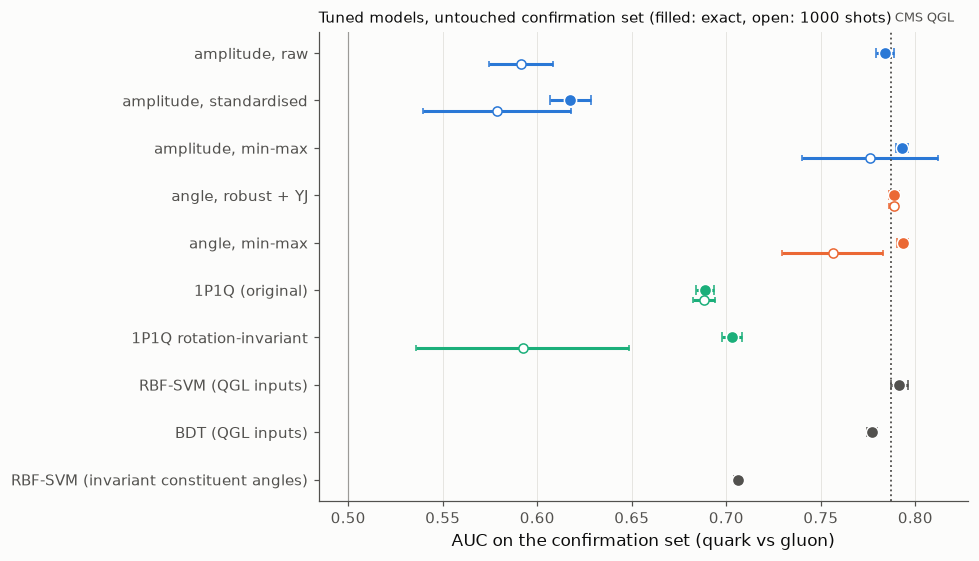

In [6]:
FAM_COLOR = {"amplitude": COLORS["series1"], "angle": COLORS["series2"], "1P1Q": COLORS["series3"], "classical": COLORS["reference"]}
fig, ax = plt.subplots(figsize=(9, 5.2))
ypos = np.arange(len(MODELS))[::-1]
for yp, name in zip(ypos, MODELS):
    fam = next(r["family"] for r in records if r["model"] == name)
    c, cs = stat(name, "conf_auc")
    ax.errorbar(c, yp, xerr=cs, fmt="o", color=FAM_COLOR[fam], markersize=8, markeredgecolor="white", capsize=3)
    s1000, s1000s = stat(name, "conf_auc_1000")
    if not np.isnan(s1000):
        ax.errorbar(s1000, yp - 0.22, xerr=s1000s, fmt="o", mfc="white", color=FAM_COLOR[fam], markersize=6, capsize=2)
ax.axvline(qgl_conf, color=COLORS["reference"], linestyle=":", linewidth=1.2)
ax.text(qgl_conf, len(MODELS) - 0.4, " CMS QGL", fontsize=8.5, color=COLORS["reference"], va="bottom")
ax.axvline(0.5, color=COLORS["reference"], linewidth=0.8, alpha=0.5)
ax.set_yticks(ypos, MODELS)
ax.set_xlabel("AUC on the confirmation set (quark vs gluon)")
ax.set_title("Tuned models, untouched confirmation set (filled: exact, open: 1000 shots)", loc="left", fontsize=10)
ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "fig11_final_confirmation")
plt.show()

## 6. Summary for the research log

In [7]:
print(f"- Final evaluation (CV-tuned, 400-jet subsamples x 5 seeds, confirmation file {CONFIRM_PATH.name}, {len(conf['y'])} jets); CMS QGL {qgl_conf:.3f}")
for name in MODELS:
    c, cs = stat(name, "conf_auc"); s1000, _ = stat(name, "conf_auc_1000")
    print(f"  - {name}: {c:.3f} ± {cs:.3f}" + (f" (1000 shots {s1000:.3f})" if not np.isnan(s1000) else ""))

- Final evaluation (CV-tuned, 400-jet subsamples x 5 seeds, confirmation file JetNtuple_RunIISummer16_13TeV_MC_10.h5, 69810 jets); CMS QGL 0.787
  - amplitude, raw: 0.784 ± 0.005 (1000 shots 0.591)
  - amplitude, standardised: 0.617 ± 0.011 (1000 shots 0.579)
  - amplitude, min-max: 0.793 ± 0.003 (1000 shots 0.776)
  - angle, robust + YJ: 0.789 ± 0.002 (1000 shots 0.789)
  - angle, min-max: 0.793 ± 0.003 (1000 shots 0.756)
  - 1P1Q (original): 0.689 ± 0.005 (1000 shots 0.688)
  - 1P1Q rotation-invariant: 0.703 ± 0.005 (1000 shots 0.592)
  - RBF-SVM (QGL inputs): 0.791 ± 0.005
  - BDT (QGL inputs): 0.777 ± 0.003
  - RBF-SVM (invariant constituent angles): 0.706 ± 0.002
